# Method, standard population and mapping sensitivity

These choices change the apparent distribution of burden while using the same underlying observations. Analyses below distinguish three sources of sensitivity rather than treating differences as sampling error.

In [1]:
from pathlib import Path
import json
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "contracts/organs.json").exists())
sys.path.insert(0, str(root / "pipeline/src"))
import pandas as pd
from IPython.display import display, Markdown
from visceral_pipeline.analysis.data import CACHE, load_inputs, load_results
from visceral_pipeline.analysis import comparisons, sensitivity, clustering, plots
inputs, frames = load_inputs(), load_results()
meta = json.loads((CACHE / "metadata.json").read_text())
pd.set_option("display.max_rows", 65)
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 140)


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\louis\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


## 1. Seven broad bins versus WHO fine-age ASDR

For country deaths, relative difference is 100 × (broad − published) / published. Zero published values are excluded from relative summaries and remain available as absolute pairs. The observed 70+ death share is an age-concentration proxy; no midpoint is invented for the open-ended bin. Pooling broad ages loses within-bin detail; associations with age concentration are descriptive and do not establish a causal explanation for every group.

,organ,n,p05,median,p95,world_70_plus_share,within_organ_age_rho
3,brain,185,-25.921185,-15.019661,5.648884,67.955995,0.673274
12,heart,185,-24.915631,-13.673820,6.368211,63.379022,0.651410
21,other_unallocated,185,-22.585905,-13.234861,4.477307,56.078165,0.690125
25,skin,185,-26.805727,-13.019635,5.079000,60.182980,0.502344
17,lungs,185,-23.180350,-12.642554,4.589927,58.868725,0.596003
26,small_intestine,184,-27.741882,-12.302143,6.864766,42.606231,0.287675
15,kidneys,185,-23.284987,-11.089100,5.487209,55.982744,0.584735
2,bones_joints,185,-24.549778,-10.987815,5.385371,65.443995,0.409079
11,gallbladder,185,-24.383111,-10.723046,3.738323,65.534216,0.462558
7,diabetes_endocrine,185,-19.810101,-8.668414,4.015883,55.390187,0.498035


Across-group rho (signed method difference vs global 70+ share): -0.6867630700778643


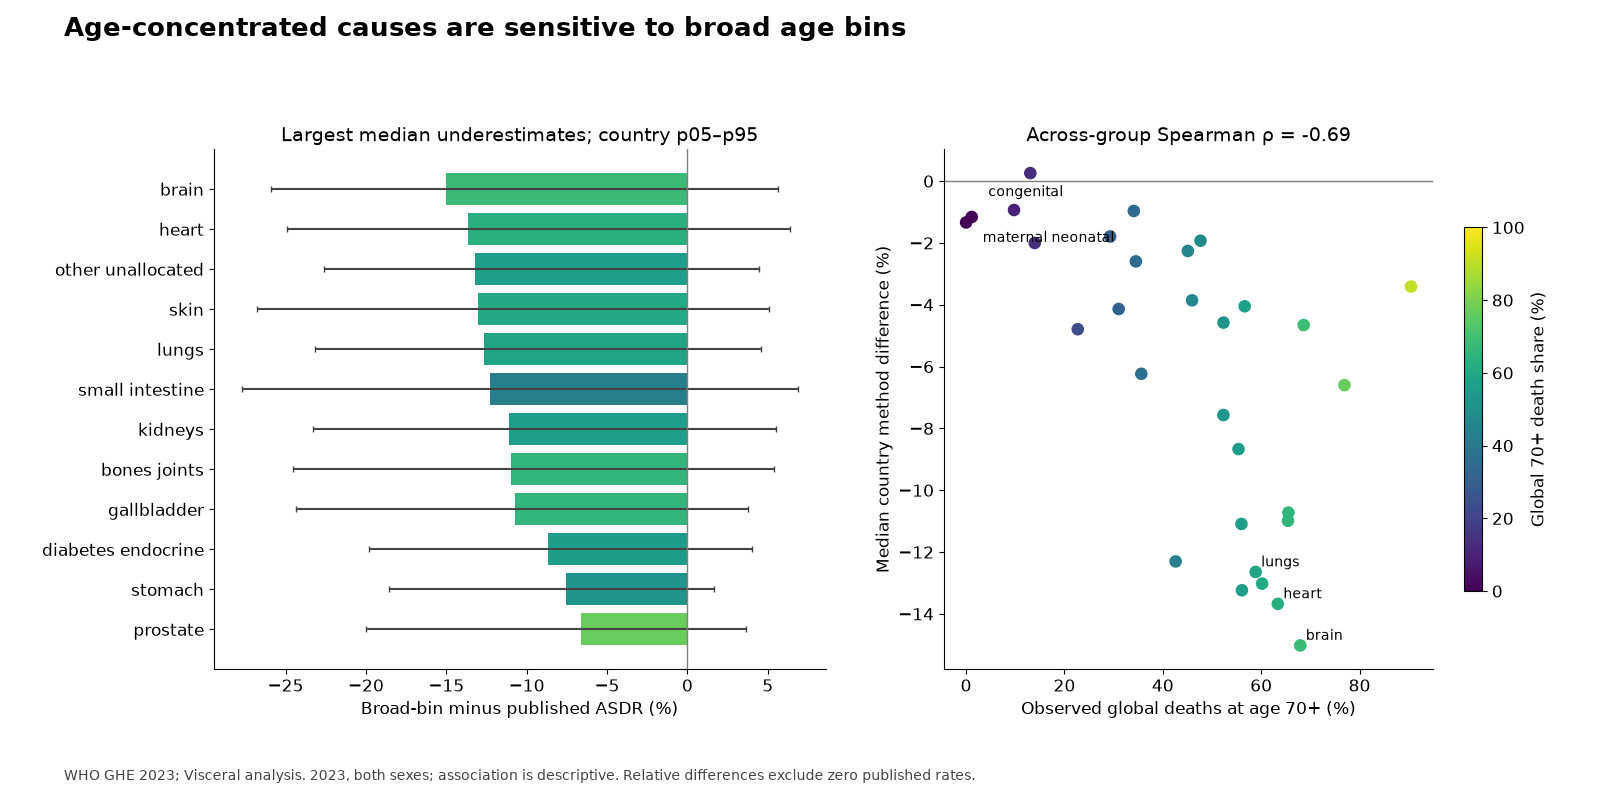

In [2]:
display(frames['methods_summary'].sort_values('median'))
print('Across-group rho (signed method difference vs global 70+ share):',meta['age_bias_group_rho'])
plots.display_figure(plots.methods(frames,meta))

## 2. Choice among five standard populations

WHO2026, WHO2021, Segi, Scandinavian and European2013 are all collapsed to the same seven bins and normalized. Comparing all of them by the same broad-bin method isolates the choice of weights; using published fine-age WHO2026 only for the baseline would conflate two methods. Rank correlations below are across countries per group. The global table shows how the ranking of groups changes under each standard.

In [3]:
standard_rates, standard_ranks, standard_rho, world = sensitivity.standard_sensitivity(inputs['ages'])
display(standard_rho.query("standard!='WHO2026'").sort_values(['measure','rho']))
display(world.pivot(index=['measure','organ'],columns='standard',values='rank'))
display(standard_ranks.assign(abs_change=lambda x:x.rank_change.abs()).sort_values('abs_change',ascending=False).groupby(['measure','standard'],sort=False).head(3)[['measure','standard','organ','location','rank_a','rank_b','rank_change']])

,measure,standard,organ,n,rho,max_abs_rank_change
87,dalys,Segi,skin,185,0.941604,68.0
118,dalys,WHO2021,skin,185,0.966428,56.0
84,dalys,Segi,ovaries,185,0.968680,67.0
83,dalys,Segi,other_unallocated,185,0.970098,47.0
91,dalys,Segi,thyroid,185,0.972539,71.0
...,...,...,...,...,...,...
165,deaths,European2013,eyes,185,1.000000,0.0
175,deaths,European2013,muscles,185,NaN,0.0
206,deaths,Scandinavian,muscles,185,NaN,0.0
237,deaths,Segi,muscles,185,NaN,0.0


standard                     European2013  Scandinavian  Segi  WHO2021  WHO2026
measure organ                                                                  
dalys   bladder                      28.0          28.0  28.0     28.0     28.0
        blood_immune                 13.0          12.0  12.0     11.0     12.0
        bones_joints                  7.0           8.0   9.0      9.0      7.0
        brain                         2.0           2.0   4.0      3.0      2.0
        breast                       20.0          20.0  19.0     19.0     20.0
        colon_rectum                 18.0          19.0  20.0     20.0     19.0
        congenital                   19.0          16.0  13.0     14.0     16.0
        diabetes_endocrine            8.0          10.0  10.0     10.0     10.0
        ears                         12.0          14.0  15.0     15.0     13.0
        esophagus                    25.0          24.0  24.0     24.0     25.0
        eyes                         21.0          21.0  21.0     21.0     21.0
        gallbladder                  26.0          25.0  25.0     25.0     26.0
        heart                         3.0           4.0   5.0      4.0      3.0
        infections_systemic          10.0           9.0   7.0      8.0      9.0
        injuries                      4.0           3.0   2.0      2.0      4.0
        kidneys                      14.0          15.0  16.0     16.0     15.0
        liver                        11.0          11.0  14.0     13.0     11.0
        lungs                         1.0           1.0   1.0      1.0      1.0
        maternal_neonatal             9.0           6.0   3.0      5.0      8.0
        mental_substance              6.0           5.0   6.0      6.0      6.0
        other_unallocated             5.0           7.0   8.0      7.0      5.0
        ovaries                      27.0          27.0  27.0     27.0     27.0
        pancreas                     22.0          22.0  22.0     22.0     22.0
        prostate                     23.0          26.0  26.0     26.0     24.0
        skin                         16.0          17.0  17.0     17.0     17.0
        small_intestine              15.0          13.0  11.0     12.0     14.0
        stomach                      17.0          18.0  18.0     18.0     18.0
        testes                       30.0          30.0  30.0     30.0     30.0
        thyroid                      29.0          29.0  29.0     29.0     29.0
        uterus_cervix                24.0          23.0  23.0     23.0     23.0
deaths  bladder                      23.0          24.0  25.0     24.0     24.0
        blood_immune                 13.0          14.0  12.0     14.0     14.0
        bones_joints                 24.0          26.0  26.0     26.0     25.0
        brain                         2.0           3.0   3.0      3.0      3.0
        breast                       15.0          15.0  16.0     15.0     15.0
        colon_rectum                 11.0          12.0  14.0     12.0     12.0
        congenital                   25.0          18.0  15.0     16.0     20.0
        diabetes_endocrine            6.0           6.0   8.0      8.0      6.0
        ears                         29.0          29.0  29.0     29.0     29.0
        esophagus                    18.0          17.0  20.0     18.0     18.0
        eyes                         30.0          30.0  30.0     30.0     30.0
        gallbladder                  21.0          23.0  23.0     23.0     23.0
        heart                         1.0           1.0   2.0      1.0      1.0
        infections_systemic           9.0           8.0   7.0      7.0      8.0
        injuries                      5.0           4.0   4.0      4.0      4.0
        kidneys                       8.0          10.0  11.0     10.0      9.0
        liver                         7.0           7.0   9.0      9.0      7.0
        lungs                         3.0           2.0   1.0      2.0      2.0


,measure,standard,organ,location,rank_a,rank_b,rank_change
23868,dalys,Segi,thyroid,BTN,146.0,75.0,71.0
23833,dalys,Segi,skin,BRN,44.0,112.0,-68.0
12336,dalys,WHO2021,thyroid,BTN,146.0,78.0,68.0
27364,dalys,Segi,ovaries,QAT,68.0,135.0,-67.0
31931,deaths,Segi,blood_immune,LUX,50.0,109.0,-59.0
29730,deaths,Segi,blood_immune,CHE,90.0,149.0,-59.0
31187,deaths,Segi,blood_immune,IRL,58.0,117.0,-59.0
15832,dalys,WHO2021,ovaries,QAT,68.0,124.0,-56.0
12301,dalys,WHO2021,skin,BRN,44.0,100.0,-56.0
20582,deaths,WHO2021,thyroid,MDV,84.0,29.0,55.0


## 3. Alternative broad cause attribution

`cause_map_alt.csv` preserves every primary node and its partition. COVID-19 and TB move to systemic infections, diabetes to pancreas, and the whole inseparable mental/substance aggregate to brain. Hypertensive heart disease stays heart. Other circulatory disease stays unallocated because its label is not exclusively cardiac. Descendant labels follow their primary ancestor; no death is counted twice. This is an illustrative attribution scenario, not an alternative medical ontology. Unallocated shares stay unchanged because all moves are between allocated groups. Shares use the sum of primary counts, avoiding inconsistent published root totals.

,measure,organ,rank_base,rank_alt,count_share_base,count_share_alt
4190,deaths,injuries,4.0,4.0,7.844164,7.844164
4191,deaths,other_unallocated,5.0,5.0,6.309555,6.309555
6633,dalys,brain,2.0,1.0,10.967672,18.262877
6634,dalys,eyes,21.0,20.0,0.655598,0.655598
6635,dalys,ears,13.0,12.0,1.913937,1.913937
6636,dalys,thyroid,29.0,28.0,0.049818,0.049818
6637,dalys,lungs,1.0,3.0,12.737716,9.789548
6638,dalys,heart,3.0,2.0,9.501181,9.501181
6639,dalys,esophagus,25.0,24.0,0.405952,0.405952
6640,dalys,stomach,18.0,17.0,0.888674,0.888674


0.05  0.50  0.95
measure organ                                
dalys   bladder               0.0   1.0   1.0
        blood_immune          0.0   1.0   1.0
        bones_joints         -1.0   1.0   2.0
        brain                 0.0   1.0   3.0
        breast                0.0   1.0   1.8
        colon_rectum          0.0   0.0   1.0
        congenital            0.0   1.0   1.0
        diabetes_endocrine  -17.0 -13.0  -9.0
        ears                  0.0   1.0   1.0
        esophagus             0.0   1.0   1.0
        eyes                  0.0   1.0   2.0
        gallbladder           0.0   1.0   2.0
        heart                -1.0   0.0   1.0
        infections_systemic   0.0   6.0  14.0
        injuries             -1.0   0.0   1.8
        kidneys               0.0   1.0   1.0
        liver                 0.0   1.0   1.0
        lungs                -3.0  -1.0   1.0
        maternal_neonatal    -0.8   0.0   1.0
        mental_substance    -29.5 -24.5 -21.5
        muscles               0.5   0.5   0.5
        other_unallocated    -1.0   0.0   2.0
        ovaries               0.0   1.0   1.0
        pancreas              7.2  16.0  20.0
        prostate              0.0   1.0   2.0
        skin                  0.0   1.0   1.0
        small_intestine       0.0   1.0   1.0
        stomach               0.0   1.0   1.0
        testes                1.0   1.0   1.0
        thyroid               1.0   1.0   1.0
        uterus_cervix         0.0   1.0   2.0
deaths  bladder               0.0   1.0   2.0
        blood_immune         -1.0   0.0   1.0
        bones_joints          0.0   1.0   2.0
        brain                 0.0   0.0   1.0
        breast               -1.0   0.0   1.0
        colon_rectum         -2.0   0.0   1.0
        congenital           -1.0   0.0   1.0
        diabetes_endocrine  -19.0 -12.0  -6.0
        ears                  1.0   1.0   1.0
        esophagus            -1.0   1.0   1.0
        eyes                  0.5   0.5   1.0
        gallbladder          -1.0   0.0   2.0
        heart                 0.0   0.0   1.0
        infections_systemic   0.0   5.0  14.0
        injuries             -1.0   0.0   0.0
        kidneys              -1.0   0.0   0.0
        liver                -2.0   0.0   0.8
        lungs                -2.0   0.0   0.0
        maternal_neonatal    -1.0   0.0   1.0
        mental_substance    -19.0  -7.0  -3.0
        muscles               0.5   0.5   0.5
        other_unallocated    -1.0   0.0   1.0
        ovaries               0.0   1.0   2.0
        pancreas              2.2  10.0  17.0
        prostate             -1.0   0.0   1.0
        skin                 -1.0   0.0   2.0
        small_intestine      -1.0   0.0   1.0
        stomach              -1.0   0.0   1.0
        testes                0.5   1.0   1.0
        thyroid               0.0   1.0   1.0
        uterus_cervix        -1.0   0.0   1.0

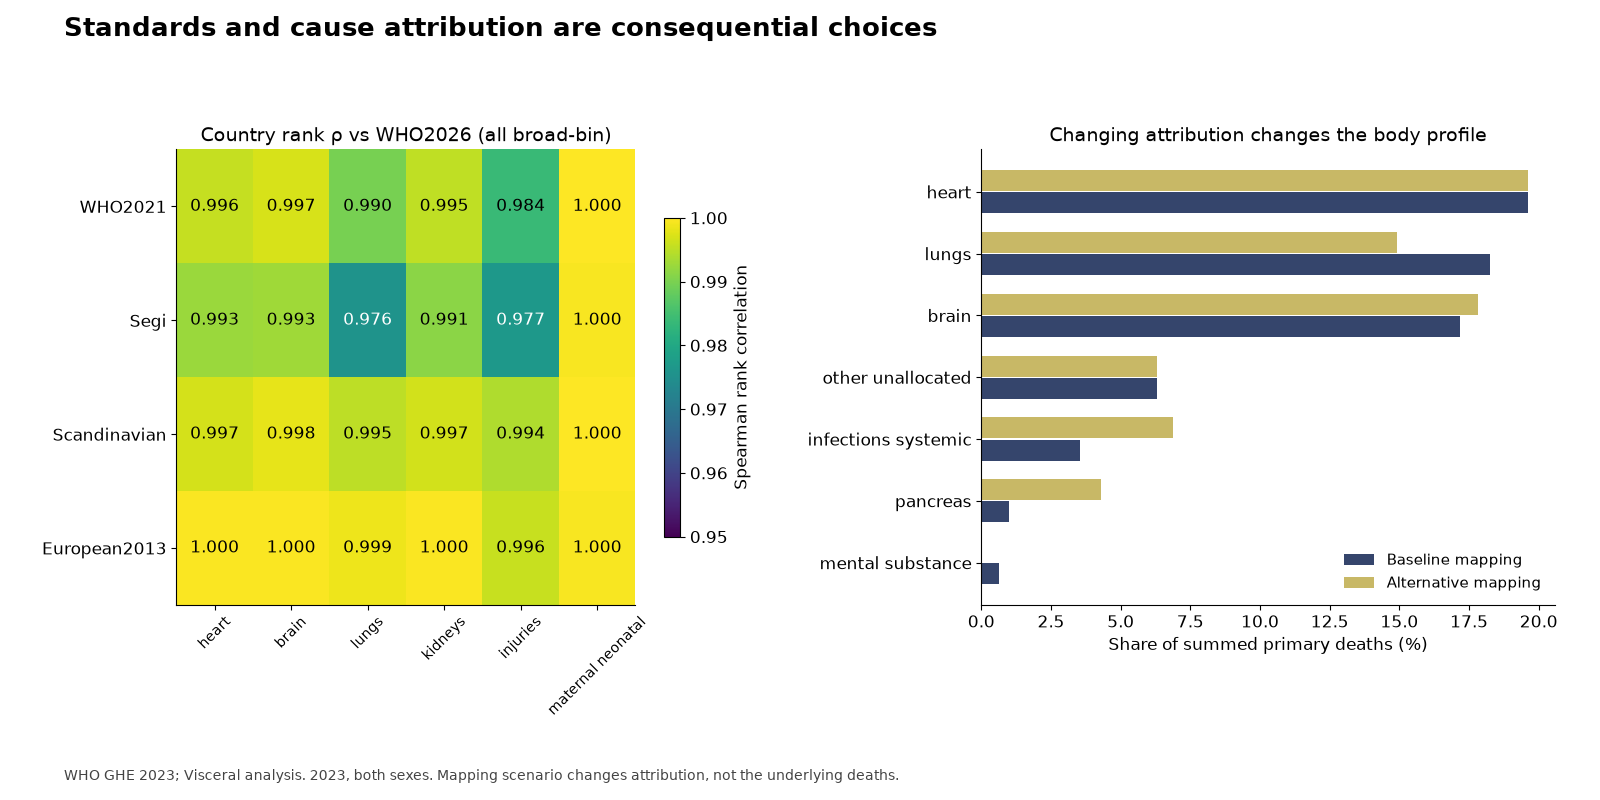

In [4]:
alternative = sensitivity.mapping_comparison(inputs['burden'].query("year==2023 and sex=='both'"),inputs['alternative'])
display(alternative.query("location=='WLD'")[['measure','organ','rank_base','rank_alt','count_share_base','count_share_alt']])
display(alternative.query("location!='WLD'").groupby(['measure','organ'])['rank_change'].quantile([.05,.5,.95]).unstack())
plots.display_figure(plots.standards_mapping(frames,meta))

## Interpretation

Standard population and mapping are explicit modeling choices; neither produces a uniquely correct body profile. Main production country death ASDRs retain WHO fine ages, while WLD and DALYs retain the documented approximation. These findings describe burden associated with mapped causes and should not be read as diagnosis, organ function, or estimates of a causal intervention.